# Week 4 · Part A — Nine charts that are wrong, taken apart
**Data Visualization (CDB601220) — Time-Series, Proportions & Hierarchies**

For each of the nine cases this notebook does four things, in this order:

1. **Rebuild** the published chart from its recipe and check the **self-check numbers** (an `assert` fails if the rebuild is not faithful).
2. **Evidence** — a code cell that computes the numbers the diagnosis rests on.
3. **Redesign** — the honest chart, actually plotted.
4. **Diagnosis** — conclusion invited, the decoy and why it fails, the mechanism, the redesign.

Every figure is saved to `outputs/partA/`. All data is synthetic course data.

> **How to run:** put this notebook in `week4/assignments/` (next to `tslib.py`, `vizlib.py` and `data/`), then *Kernel → Restart & Run All*.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

HERE = Path.cwd()                      # run the notebook from week4/assignments
DATA = HERE / "data"
OUT  = HERE / "outputs"; OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(HERE))

import tslib as T                      # Week 4 toolkit (imports Week 3's vizlib)
from tslib import PALETTE, style_defaults, save_fig
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"]
SOFT = PALETTE["ink_soft"]
SRC = "Source: CDB601220 Week 4 synthetic course data (Superior University Lahore)."

PA = OUT / "partA"; PA.mkdir(exist_ok=True)

def finish(fig, name, note=SRC):
    """fig.savefig BEFORE plt.show() (Week 3 rule), then show."""
    save_fig(fig, PA / name, note=note)
    plt.show()

def hinge_changepoint(s, margin=20):
    """Best single turning point of a continuous two-segment line (least squares)."""
    x = np.arange(len(s)); y = s.to_numpy(float); best = None
    for k in range(margin, len(s) - margin):
        X = np.column_stack([np.ones(len(x)), x, np.maximum(0, x - k)])
        b = np.linalg.lstsq(X, y, rcond=None)[0]
        sse = float(((y - X @ b) ** 2).sum())
        if best is None or sse < best[0]:
            best = (sse, k, b)
    return s.index[best[1]], best[2]

def say(text):
    display(Markdown(text))

---
## Case 1 · "Orders peak in Q1 and collapse every year — a clear annual cycle"
`case01_orders_stringdate.csv` · recipe: sort the 24 rows by the `month` column, plot `orders` as a line with markers, y from zero.

runs of (direction, length): [[1.0, 3], [-1.0, 1], [1.0, 11], [-1.0, 1], [1.0, 7]]
two drops: [-958.0, -978.0]


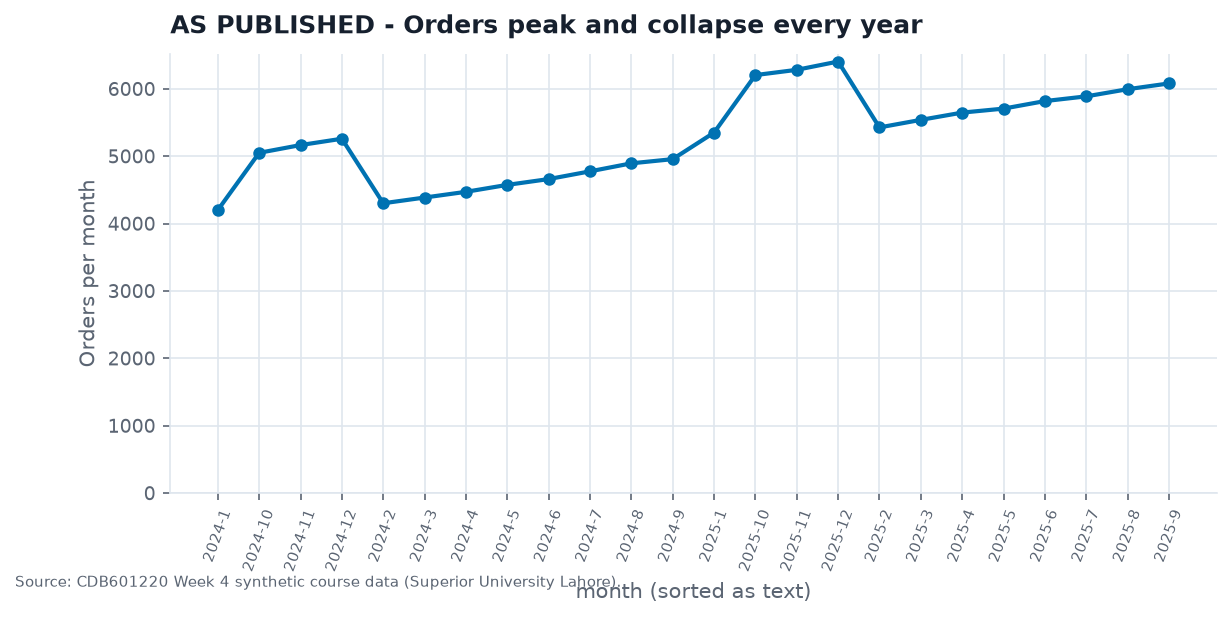

In [2]:
c1 = pd.read_csv(DATA / "case01_orders_stringdate.csv")
pub1 = c1.sort_values("month").reset_index(drop=True)      # <- the recipe: sort the TEXT
d1 = pub1.orders.diff()

# ---- self-check (brief): 24 points; climbs 4, drops 958, climbs 11, drops 978, climbs again
assert len(pub1) == 24
assert sorted(d1.dropna()[d1.dropna() < 0].tolist()) == [-978, -958]
signs = np.sign(d1.dropna()).tolist()
runs = []
for s_ in signs:
    if runs and runs[-1][0] == s_: runs[-1][1] += 1
    else: runs.append([s_, 1])
print("runs of (direction, length):", runs)
print("two drops:", d1[d1 < 0].tolist())

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(24), pub1.orders, marker="o", color=BLUE)
ax.set_xticks(range(24)); ax.set_xticklabels(pub1.month, rotation=70, fontsize=7)
ax.set_ylim(0, None)
ax.set_title("AS PUBLISHED - Orders peak and collapse every year")
ax.set_xlabel("month (sorted as text)"); ax.set_ylabel("Orders per month")
finish(fig, "case01_published.png")

In [3]:
# ---- EVIDENCE
print("dtype of month:", c1.month.dtype, "| first 6 after text sort:", pub1.month.head(6).tolist())
print("'2024-10' < '2024-2' as text?", "2024-10" < "2024-2", " (compares '1' with '2' at position 6)")
c1["when"] = pd.to_datetime(c1.month, format="%Y-%m")       # '%m' accepts '1' as well as '01'
t1 = c1.sort_values("when").reset_index(drop=True)
dt1 = t1.orders.diff().dropna()
print("after a real parse: month-to-month falls =", int((dt1 < 0).sum()), "of", len(dt1),
      "| smallest rise =", int(dt1.min()), "| largest =", int(dt1.max()))
cagr = (t1.orders.iloc[-1] / t1.orders.iloc[0]) ** (1 / 23) - 1
print(f"{t1.orders.iloc[0]:,} -> {t1.orders.iloc[-1]:,}  (+{(t1.orders.iloc[-1]/t1.orders.iloc[0]-1)*100:.1f}% in 23 months, {cagr*100:.2f}% per month compound)")
print("the two 'collapses' are Dec -> Feb jumps in the TEXT order:",
      list(zip(pub1.month[d1[d1 < 0].index - 1], pub1.month[d1[d1 < 0].index])))

dtype of month: str | first 6 after text sort: ['2024-1', '2024-10', '2024-11', '2024-12', '2024-2', '2024-3']
'2024-10' < '2024-2' as text? True  (compares '1' with '2' at position 6)
after a real parse: month-to-month falls = 0 of 23 | smallest rise = 59 | largest = 124
4,200 -> 6,405  (+52.5% in 23 months, 1.85% per month compound)
the two 'collapses' are Dec -> Feb jumps in the TEXT order: [('2024-12', '2024-2'), ('2025-12', '2025-2')]


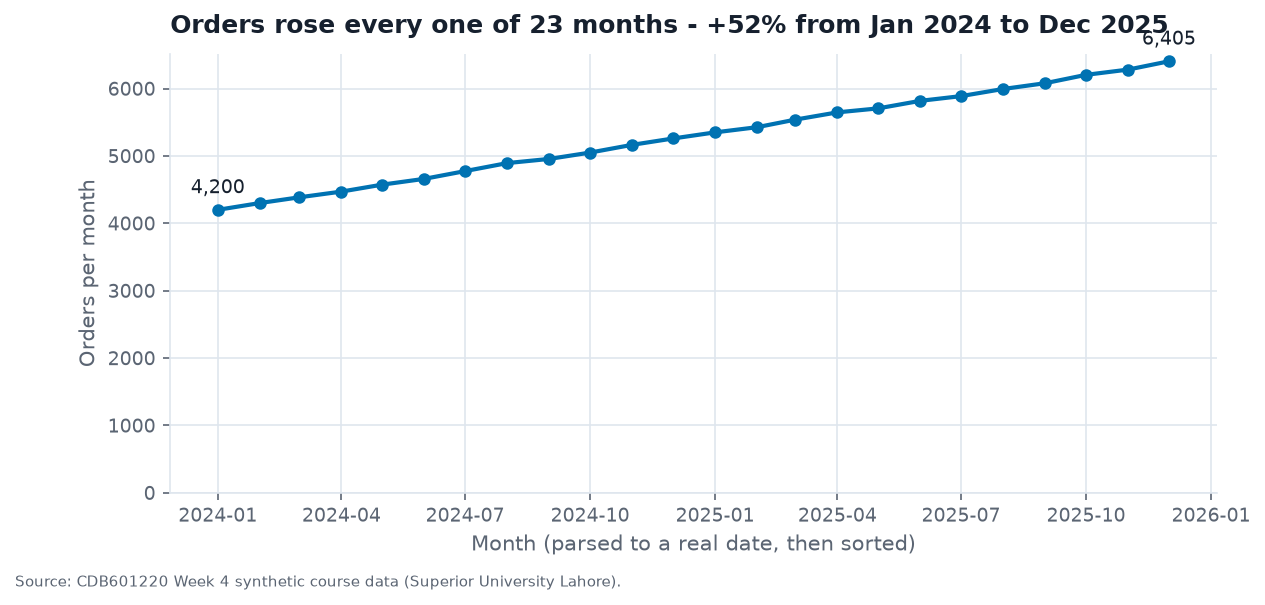

In [4]:
# ---- REDESIGN: parse, then sort chronologically
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(t1.when, t1.orders, marker="o", color=BLUE)
for i in (0, len(t1) - 1):
    ax.annotate(f"{t1.orders.iloc[i]:,}", (t1.when.iloc[i], t1.orders.iloc[i]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_ylim(0, None)
ax.set_title("Orders rose every one of 23 months - +52% from Jan 2024 to Dec 2025")
ax.set_xlabel("Month (parsed to a real date, then sorted)"); ax.set_ylabel("Orders per month")
finish(fig, "case01_redesign.png")

**Conclusion the chart invites:** orders follow a Q1-peak, then collapse, annual cycle.

**The decoy:** "maybe the business is genuinely seasonal — January/February spikes are common in retail." It does not hold *here*: after a real parse **0 of 23** month-to-month changes are negative (smallest rise +59, largest +124). A seasonal business would show falls.

**The mechanism:** `month` is text in the form `YYYY-M` with no zero padding, so sorting compares characters. `"2024-10" < "2024-2"` because `'1' < '2'` at the sixth character. Within each year, months 10, 11 and 12 jump in front of months 2–9. The two "collapses" (**−958** and **−978**) are not months at all — they are the jump from `2024-12` back to `2024-2`, and from `2025-12` back to `2025-2`. Rows affected: every month from October to December, in both years (6 of 24), plus the rows they displace (months 2–9).

**The redesign:** parse to datetime (`format="%Y-%m"`), sort by that, plot. One steady climb, 4,200 → 6,405 (+52.5%, ≈1.85%/month compound).

---
## Case 2 · "Sales grew steadily, 22%, across the quarter"
`case02_shop_closed.csv` · recipe: plot `sales_pkr_k` against the **row number** (`range(len(df))`) and add a least-squares trend line.

n=69  first=207  last=253  rise=+22%


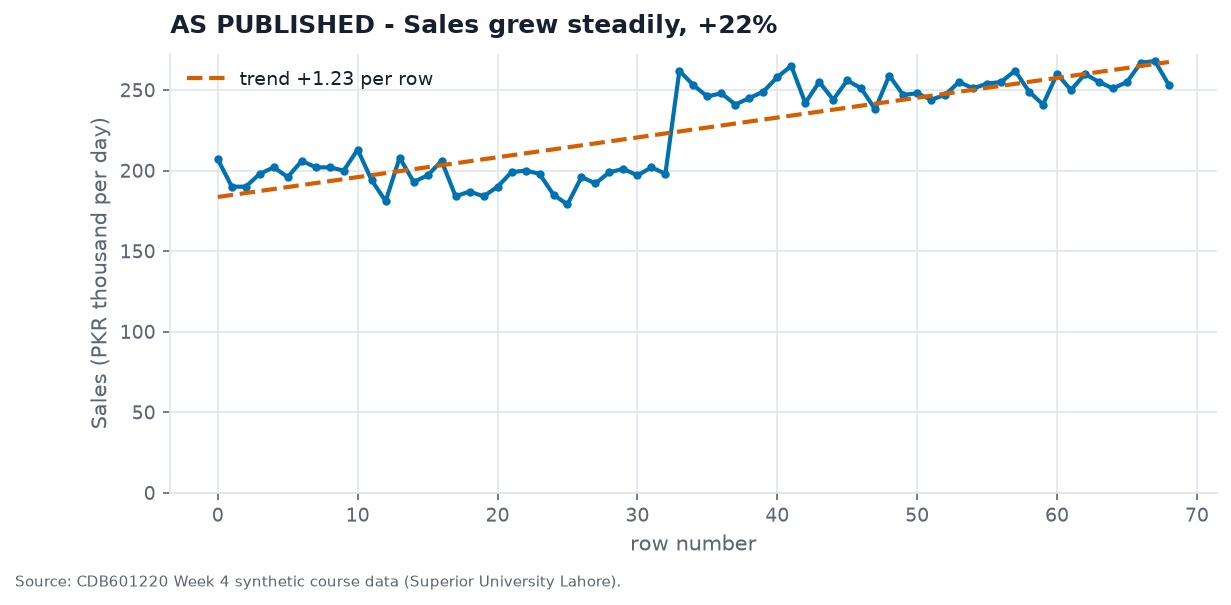

In [5]:
c2 = pd.read_csv(DATA / "case02_shop_closed.csv", parse_dates=["date"])
y2 = c2.sales_pkr_k.to_numpy()

# ---- self-check: 69 points, first 207, last 253, +22%
assert len(c2) == 69 and y2[0] == 207 and y2[-1] == 253
rise = (y2[-1] / y2[0] - 1) * 100
print(f"n={len(c2)}  first={y2[0]}  last={y2[-1]}  rise={rise:+.0f}%")
assert round(rise) == 22

x2 = np.arange(len(c2)); m2, b2 = np.polyfit(x2, y2, 1)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x2, y2, color=BLUE, marker="o", markersize=3)
ax.plot(x2, m2 * x2 + b2, color=ORANGE, linestyle="--", label=f"trend {m2:+.2f} per row")
ax.set_ylim(0, None); ax.legend()
ax.set_title("AS PUBLISHED - Sales grew steadily, +22%")
ax.set_xlabel("row number"); ax.set_ylabel("Sales (PKR thousand per day)")
finish(fig, "case02_published.png")

In [6]:
# ---- EVIDENCE: len(df) against the span of the date column
from scipy import stats
s2 = c2.set_index("date").sales_pkr_k
span = (s2.index.max() - s2.index.min()).days + 1
full2 = pd.date_range(s2.index.min(), s2.index.max(), freq="D")
missing2 = full2.difference(s2.index)
print(f"rows={len(s2)}  calendar span={span} days  -> {len(missing2)} days never recorded "
      f"({missing2.min().date()} to {missing2.max().date()}, one unbroken run: "
      f"{(pd.Series(missing2).diff().dropna() == pd.Timedelta('1D')).all()})")
pre2, post2 = s2[:missing2.min() - pd.Timedelta("1D")], s2[missing2.max() + pd.Timedelta("1D"):]
def slope_days(x):
    t = (x.index - x.index[0]).days.to_numpy(); r = stats.linregress(t, x.to_numpy(float)); return r.slope, r.pvalue
sp, pp = slope_days(pre2); sq, pq = slope_days(post2); so, po = slope_days(s2)
print(f"before the gap: n={len(pre2)}, mean={pre2.mean():.1f}, slope={sp:+.2f}/day (p={pp:.2f})")
print(f"after the gap : n={len(post2)}, mean={post2.mean():.1f}, slope={sq:+.2f}/day (p={pq:.2f})")
print(f"step across the gap: last 5 before -> first 5 after = {pre2.iloc[-5:].mean():.1f} -> {post2.iloc[:5].mean():.1f}  "
      f"({post2.iloc[:5].mean()-pre2.iloc[-5:].mean():+.1f})")
print(f"one line through everything: slope={so:+.2f}/day, p={po:.1e}  (significant - but it is fitting the STEP)")
step2 = post2.iloc[:5].mean() - pre2.iloc[-5:].mean()
print(f"first-to-last rise = {y2[-1]-y2[0]:+d}; the step across the gap alone = {step2:+.1f} -> larger than the whole rise, so the days either side of it drift DOWN on net")

rows=69  calendar span=90 days  -> 21 days never recorded (2025-02-03 to 2025-02-23, one unbroken run: True)
before the gap: n=33, mean=196.2, slope=-0.16/day (p=0.29)
after the gap : n=36, mean=252.3, slope=+0.23/day (p=0.06)
step across the gap: last 5 before -> first 5 after = 199.4 -> 250.0  (+50.6)
one line through everything: slope=+0.90/day, p=6.4e-28  (significant - but it is fitting the STEP)
first-to-last rise = +46; the step across the gap alone = +50.6 -> larger than the whole rise, so the days either side of it drift DOWN on net


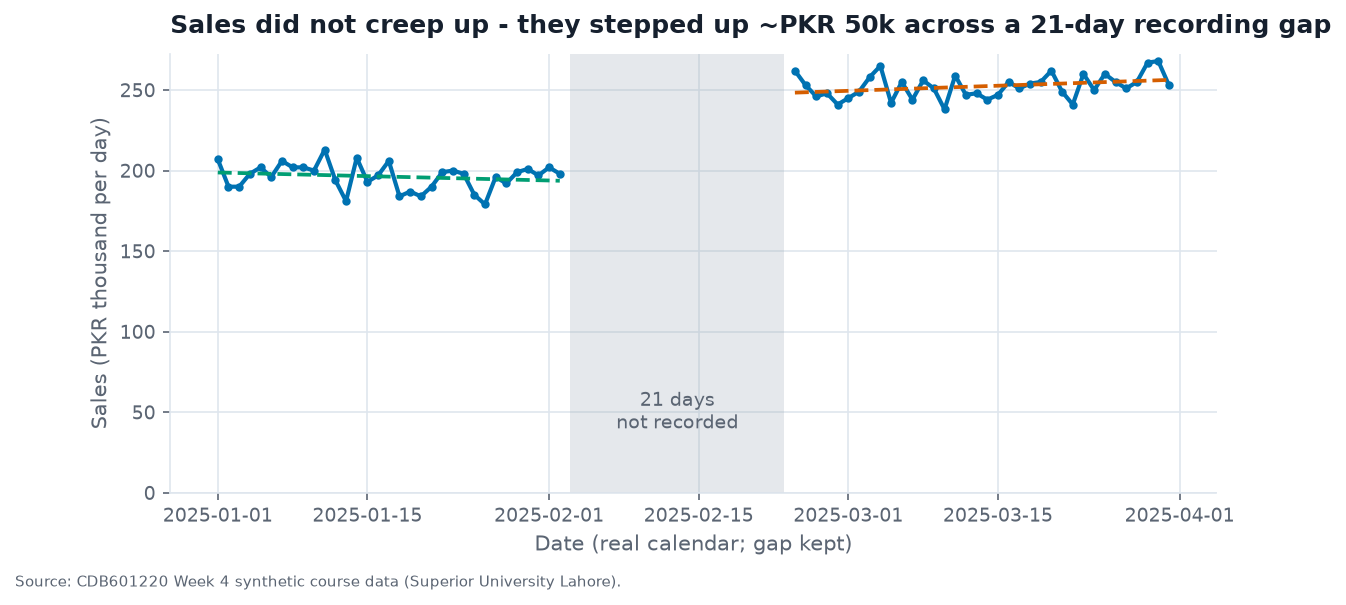

In [7]:
# ---- REDESIGN: real calendar, the gap left as a gap, each segment fitted on its own
full_s = s2.reindex(full2)                     # missing days become NaN -> line breaks
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(full_s.index, full_s, color=BLUE, marker="o", markersize=3)
ax.axvspan(missing2.min(), missing2.max(), color=GREY, alpha=0.25, lw=0)
ax.text(missing2.min() + (missing2.max() - missing2.min()) / 2, 40,
        f"{len(missing2)} days\nnot recorded", ha="center", fontsize=9, color=SOFT)
for seg, col in ((pre2, GREEN), (post2, ORANGE)):
    t = (seg.index - seg.index[0]).days.to_numpy(); m, b = np.polyfit(t, seg.to_numpy(float), 1)
    ax.plot(seg.index, m * t + b, color=col, linestyle="--", linewidth=1.8)
ax.set_ylim(0, None)
ax.set_title("Sales did not creep up - they stepped up ~PKR 50k across a 21-day recording gap")
ax.set_xlabel("Date (real calendar; gap kept)"); ax.set_ylabel("Sales (PKR thousand per day)")
finish(fig, "case02_redesign.png")

**Conclusion the chart invites:** sales grew steadily and steadily — about 22% — through the quarter.

**The decoy:** "the trend line is just fitting noise." It is not: a line through all 69 days has a significant slope (p < 0.001). The trend is *real as arithmetic* — the problem is what it is made of.

**The mechanism:** plotting against row number deletes the calendar. The file holds trading days only: **69 rows across a 90-day span**, so **21 consecutive days (3–23 February)** have no row and vanish from the x-axis. Fitted separately, the two halves are essentially flat: **−0.16/day (p = 0.29)** before the gap, **+0.23/day (p = 0.06)** after. The whole rise lives in a **step of about +50 (mean 196 → 252)** across the missing weeks. "Steady 22% growth" is a level shift hidden by a closed axis.

**The redesign:** the real date axis, the 21 unrecorded days shown as a shaded gap (the line breaks), and each segment fitted on its own. Why the shop was closed is a business question the data cannot answer, so the chart does not guess — it shows that something changed *during* the gap.

---
## Case 3 · "Peak load jumped 43% overnight on 1 July"
`case03_bandwidth_levels.csv` · recipe: resample `concurrent_users` to daily with `.sum()`, line, y from zero.

June daily mean (sum) = 8,782   July = 12,543   change = +43%


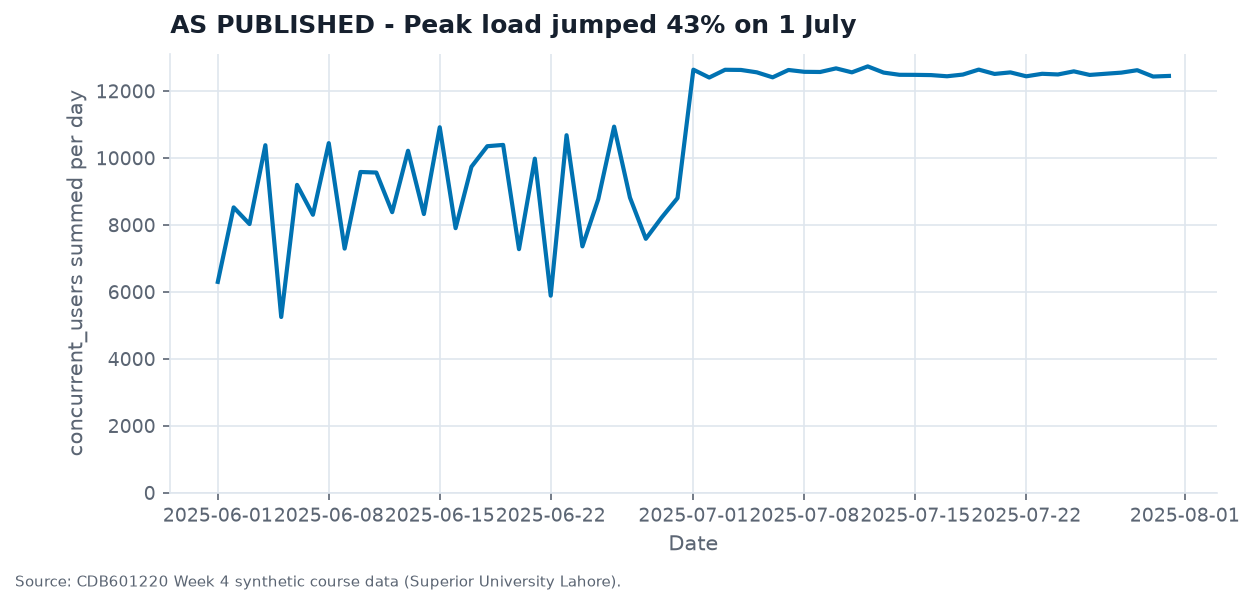

In [8]:
c3 = pd.read_csv(DATA / "case03_bandwidth_levels.csv", parse_dates=["ts"]).set_index("ts")
sum3 = c3.concurrent_users.resample("D").sum()

jun, jul = sum3.loc["2025-06"].mean(), sum3.loc["2025-07"].mean()
print(f"June daily mean (sum) = {jun:,.0f}   July = {jul:,.0f}   change = {(jul/jun-1)*100:+.0f}%")
assert abs(jun - 8800) < 100 and abs(jul - 12500) < 100 and round((jul/jun-1)*100) == 43

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(sum3.index, sum3, color=BLUE)
ax.set_ylim(0, None)
ax.set_title("AS PUBLISHED - Peak load jumped 43% on 1 July")
ax.set_xlabel("Date"); ax.set_ylabel("concurrent_users summed per day")
finish(fig, "case03_published.png")

In [9]:
# ---- EVIDENCE
rows_per_day = c3.groupby(c3.index.normalize()).size()
g3 = c3.groupby(c3.index.to_period("M"))
print("hourly rows recorded:", {str(k): int(v) for k, v in g3.size().items()}, "of", {"2025-06": 720, "2025-07": 744})
print(f"rows per day: June mean {rows_per_day.loc['2025-06'].mean():.1f}, July mean {rows_per_day.loc['2025-07'].mean():.1f}")
print(f"24 / {rows_per_day.loc['2025-06'].mean():.2f} - 1 = {(24/rows_per_day.loc['2025-06'].mean()-1)*100:+.0f}%   <- the 'jump', from row counts alone")
print(f"correlation of the daily SUM with the number of rows that day: {np.corrcoef(sum3.to_numpy(), rows_per_day.to_numpy())[0,1]:.3f}")
mean3 = c3.concurrent_users.resample("D").mean()
mm3 = g3.concurrent_users.mean()
print(f"mean concurrent users per recorded hour: June {mm3.iloc[0]:.1f} -> July {mm3.iloc[1]:.1f}  ({(mm3.iloc[1]/mm3.iloc[0]-1)*100:+.1f}%)")
bph = g3.bytes_served.sum() / g3.size()
print(f"decoy test - bytes served (a flow) per RECORDED hour: June {bph.iloc[0]:,.0f} -> July {bph.iloc[1]:,.0f} ({(bph.iloc[1]/bph.iloc[0]-1)*100:+.1f}%)")
print("bytes total per month rose", f"{(g3.bytes_served.sum().iloc[1]/g3.bytes_served.sum().iloc[0]-1)*100:+.0f}%", "- also an artefact of fewer June rows")

hourly rows recorded: {'2025-06': 493, '2025-07': 744} of {'2025-06': 720, '2025-07': 744}
rows per day: June mean 16.4, July mean 24.0
24 / 16.43 - 1 = +46%   <- the 'jump', from row counts alone
correlation of the daily SUM with the number of rows that day: 0.972
mean concurrent users per recorded hour: June 534.4 -> July 522.6  (-2.2%)
decoy test - bytes served (a flow) per RECORDED hour: June 1,061,932 -> July 1,037,295 (-2.3%)
bytes total per month rose +47% - also an artefact of fewer June rows


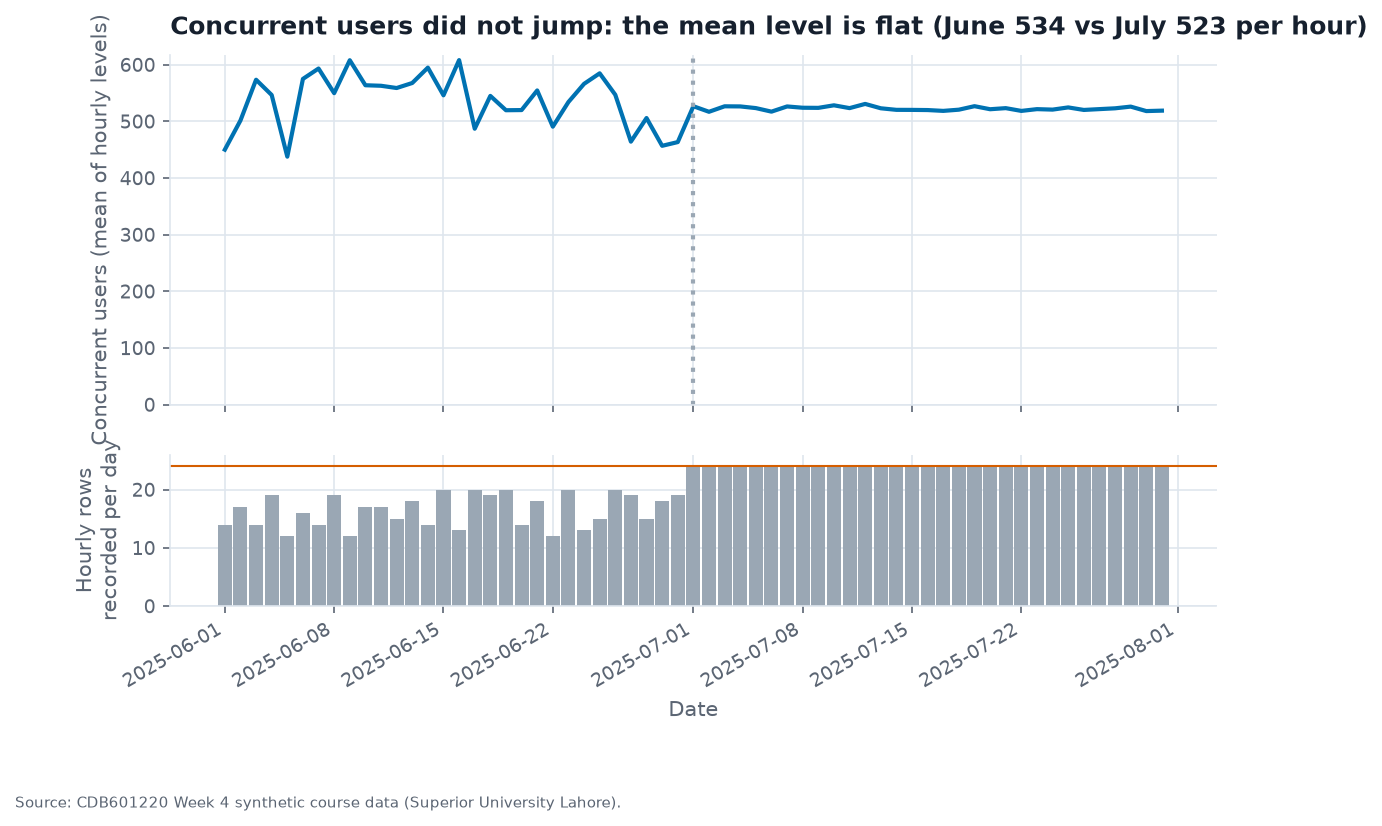

In [10]:
# ---- REDESIGN: a level is averaged, not summed; show how many hours each day really has
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax1.plot(mean3.index, mean3, color=BLUE)
ax1.axvline(pd.Timestamp("2025-07-01"), color=GREY, linestyle=":")
ax1.set_ylim(0, None)
ax1.set_title("Concurrent users did not jump: the mean level is flat (June 534 vs July 523 per hour)")
ax1.set_ylabel("Concurrent users (mean of hourly levels)")
ax2.bar(rows_per_day.index, rows_per_day, color=GREY, width=0.9)
ax2.axhline(24, color=ORANGE, linewidth=1)
ax2.set_ylim(0, 26); ax2.set_ylabel("Hourly rows\nrecorded per day"); ax2.set_xlabel("Date")
fig.autofmt_xdate()
finish(fig, "case03_redesign.png")

**Conclusion the chart invites:** a +43% demand surge arrived on 1 July.

**The decoy:** "bytes served also jumped about +47% (524 M → 772 M), so the surge is real." Bytes *is* a flow and summing it is legitimate — but it is summed over unequal numbers of rows. Per **recorded hour** it is **−2.3%** (1.062 M → 1.037 M). The decoy dissolves under the same correction.

**The mechanism:** `concurrent_users` is a **level** (users connected at an instant). `.sum()` of a level multiplies the level by *how many readings fell in the day*. June has only **493 of 720** hourly rows (**16.4 per day**), July has **744 of 744 (24 per day)**. `24 / 16.43 − 1 = +46%` — the "jump" is arithmetic on row counts, and the daily sum correlates **0.97** with the row count. Rows jump from 19 to 24 per day on 1 July: the step on the chart *is* the collector's coverage changing.

**The redesign:** daily **mean** of the level (the right aggregation for a level; use `max` if "peak load" is the real question), with the rows-per-day bars underneath so the reader can see the coverage problem. Mean concurrency: **534 → 523 (−2.2%)**.

---
## Case 4 · "The new checkout flow started working on 7 September"
`case04_intervention_lag.csv` · recipe: raw conversion in grey, 31-day **trailing** mean on top, read the turning point off the smoothed line.

trailing 31-day mean bottoms out on 2025-09-07


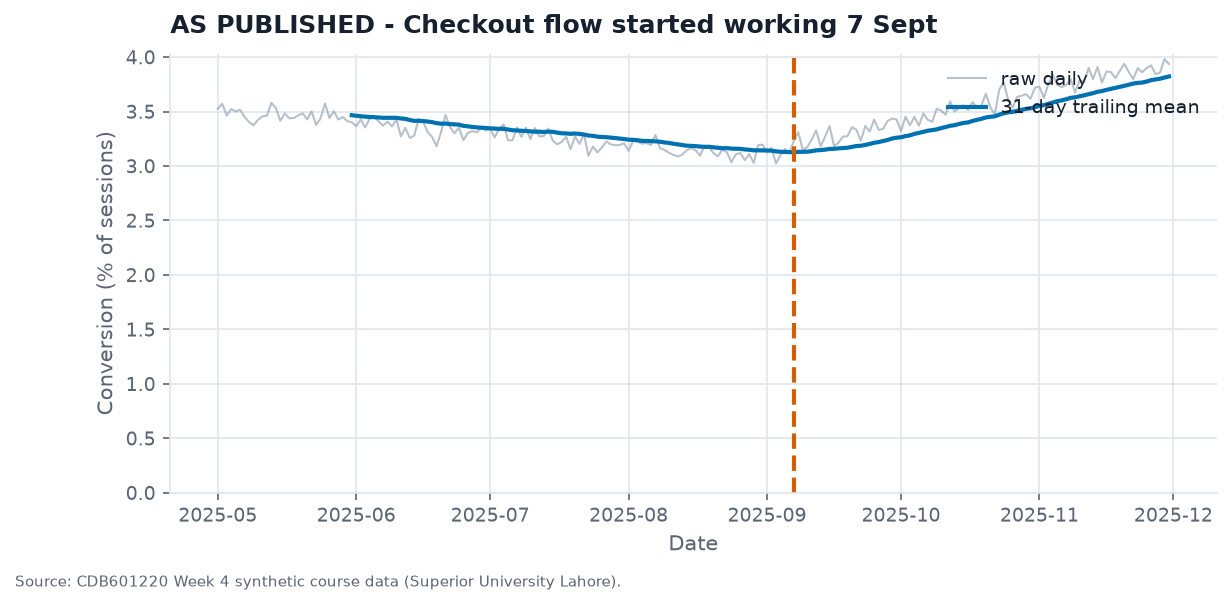

In [11]:
c4 = pd.read_csv(DATA / "case04_intervention_lag.csv", parse_dates=["date"]).set_index("date").conversion_pct
trail31 = c4.rolling(31).mean()
turn_pub = trail31.idxmin()
print("trailing 31-day mean bottoms out on", turn_pub.date())
assert turn_pub == pd.Timestamp("2025-09-07")          # self-check

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(c4.index, c4, color=GREY, alpha=0.7, linewidth=1, label="raw daily")
ax.plot(trail31.index, trail31, color=BLUE, label="31-day trailing mean")
ax.axvline(turn_pub, color=ORANGE, linestyle="--")
ax.set_ylim(0, None); ax.legend(loc="upper right")
ax.set_title("AS PUBLISHED - Checkout flow started working 7 Sept")
ax.set_xlabel("Date"); ax.set_ylabel("Conversion (% of sessions)")
finish(fig, "case04_published.png")

In [12]:
# ---- EVIDENCE
lg = T.lag_at_turn(c4, 31, how="min")
cp, coef = hinge_changepoint(c4)
print(f"trailing turn {lg['trailing_turn'].date()} | centred turn {lg['centred_turn'].date()} | "
      f"gap = {lg['lag_periods']} days vs half-window {lg['half_window']}")
print(f"independent estimate (two-segment least squares on the RAW series): {cp.date()} "
      f"(slope before {coef[1]:+.4f}, after {coef[1]+coef[2]:+.4f} pct-points/day)")
print(f"raw minimum day: {c4.idxmin().date()} ({c4.min():.2f}%)")
for w in (7, 14, 31):
    t_, c_ = c4.rolling(w).mean().idxmin(), c4.rolling(w, center=True).mean().idxmin()
    print(f"  window {w:>2}: trailing {t_.date()}  centred {c_.date()}  lag {(t_-c_).days} days  (w//2 = {w//2})")

trailing turn 2025-09-07 | centred turn 2025-08-23 | gap = 15 days vs half-window 15
independent estimate (two-segment least squares on the RAW series): 2025-08-28 (slope before -0.0035, after +0.0092 pct-points/day)
raw minimum day: 2025-09-03 (3.02%)
  window  7: trailing 2025-08-29  centred 2025-08-26  lag 3 days  (w//2 = 3)
  window 14: trailing 2025-09-03  centred 2025-08-28  lag 6 days  (w//2 = 7)
  window 31: trailing 2025-09-07  centred 2025-08-23  lag 15 days  (w//2 = 15)


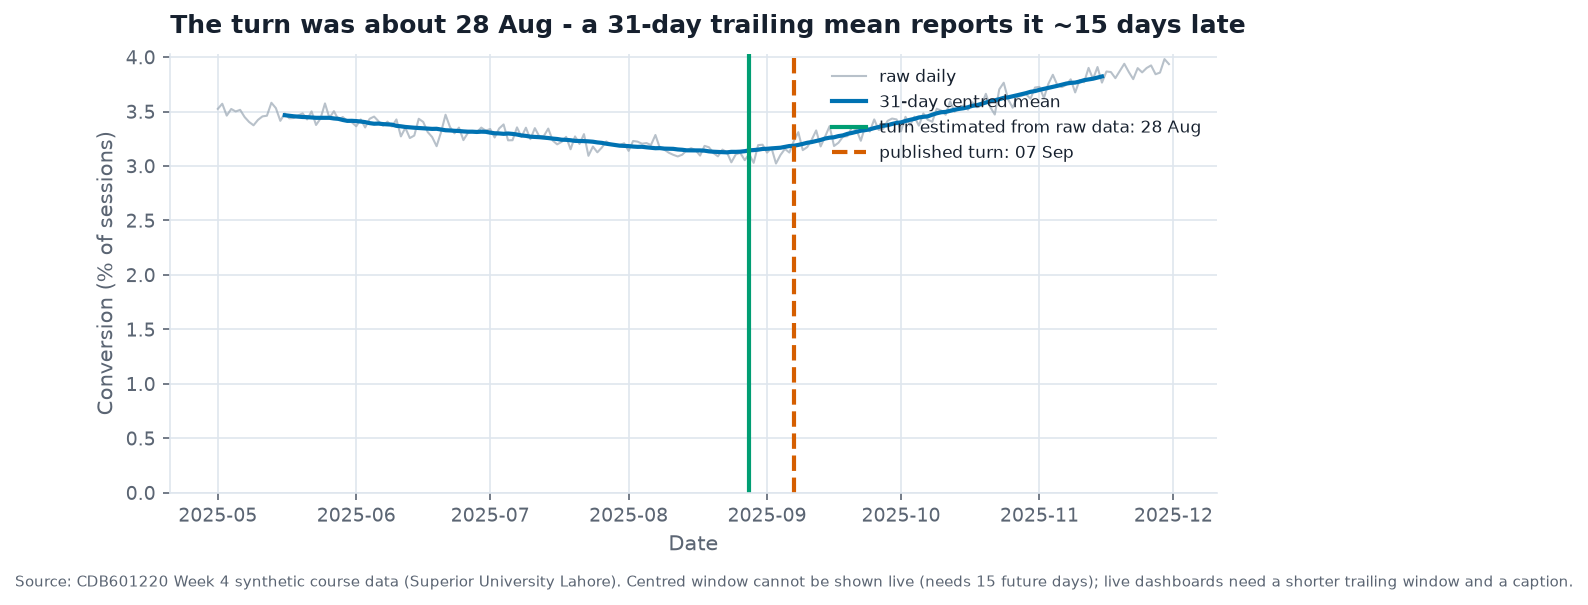

In [13]:
# ---- REDESIGN: centred mean for the historical read + the independently estimated turn
cent31 = c4.rolling(31, center=True).mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(c4.index, c4, color=GREY, alpha=0.7, linewidth=1, label="raw daily")
ax.plot(cent31.index, cent31, color=BLUE, label="31-day centred mean")
ax.axvline(cp, color=GREEN, linewidth=2, label=f"turn estimated from raw data: {cp:%d %b}")
ax.axvline(turn_pub, color=ORANGE, linestyle="--", label="published turn: 07 Sep")
ax.set_ylim(0, None); ax.legend(loc="upper right", fontsize=8)
ax.set_title("The turn was about 28 Aug - a 31-day trailing mean reports it ~15 days late")
ax.set_xlabel("Date"); ax.set_ylabel("Conversion (% of sessions)")
finish(fig, "case04_redesign.png",
       note=SRC + " Centred window cannot be shown live (needs 15 future days); live dashboards need a shorter trailing window and a caption.")

**Conclusion the chart invites:** the new checkout flow began working on 7 September.

**The decoy:** "maybe the release really went live 7 Sept — the fix needs time to show." Release date is not the question; *when did the data turn?* An estimate that does not use any smoothing window (a two-segment line fitted to the raw series) puts the turn at **28 Aug**, and the raw minimum is 3 Sept — both before 7 Sept.

**The mechanism:** a trailing window of length *w* cannot see a turn until it has filled with post-turn days, so its extreme lands about **w/2** late. Measured with `tslib.lag_at_turn`: trailing **7 Sep** vs centred **23 Aug** = **15 days = half the 31-day window**. This is arithmetic, not a bug. (The centred minimum, 23 Aug, is itself a little early because a V-shape smooths asymmetrically; the raw-data fit, 28 Aug, is the best estimate. With a 7-day window the lag shrinks to 3 days.)

**The redesign:** show the centred mean for the historical read and mark the independently estimated turn; keep the published date as a dashed comparison. For a live dashboard use a shorter trailing window and say in the caption that the turn is reported late by about half the window.

---
## Case 5 · "Revenue has fallen for six straight months"
`case05_revenue_window.csv` · recipe: take **May–November 2025** only, line with markers, **y from zero**.

n=7  158.8 -> 92.2  (-41.9%)  falls in a row: 6


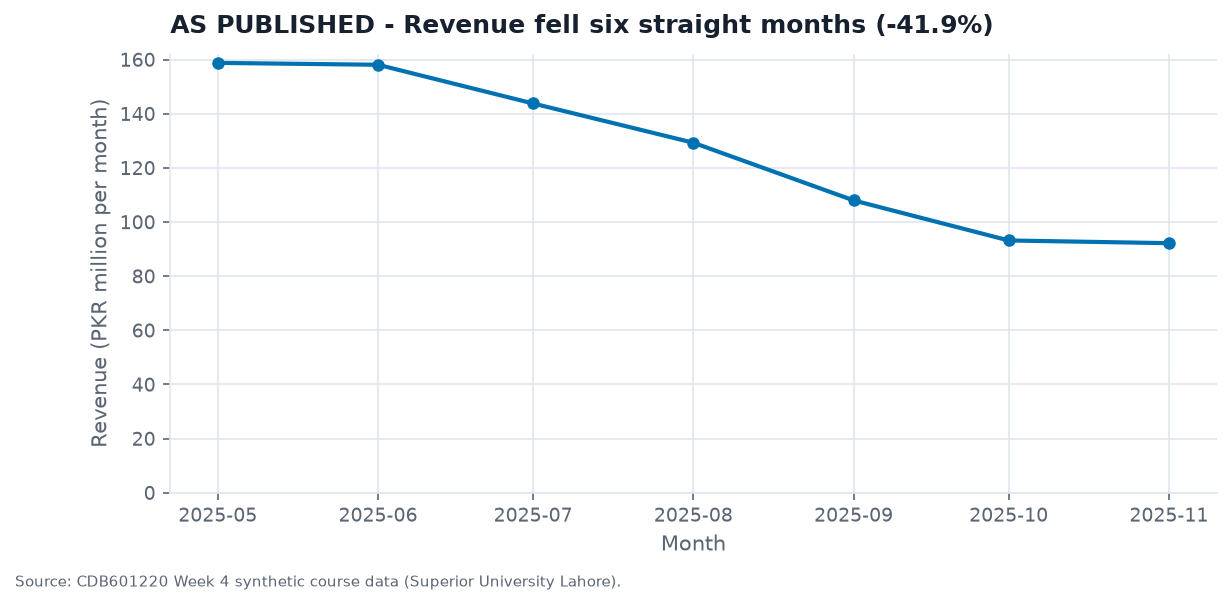

In [14]:
c5 = pd.read_csv(DATA / "case05_revenue_window.csv")
c5["when"] = pd.to_datetime(c5.month, format="%Y-%m"); s5 = c5.set_index("when").revenue_pkr_m
w5 = s5["2025-05":"2025-11"]
fall = (w5.iloc[-1] / w5.iloc[0] - 1) * 100
print(f"n={len(w5)}  {w5.iloc[0]:.1f} -> {w5.iloc[-1]:.1f}  ({fall:+.1f}%)  falls in a row: {int((w5.diff().dropna() < 0).sum())}")
assert len(w5) == 7 and round(w5.iloc[0], 1) == 158.8 and round(w5.iloc[-1], 1) == 92.2 and round(fall, 1) == -41.9

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(w5.index, w5, color=BLUE, marker="o")
ax.set_ylim(0, None)
ax.set_title("AS PUBLISHED - Revenue fell six straight months (-41.9%)")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue (PKR million per month)")
finish(fig, "case05_published.png")

In [15]:
# ---- EVIDENCE
by_year = s5.groupby(s5.index.year).sum()
print("annual revenue:", by_year.round(1).to_dict(), "| growth:", (by_year.pct_change().dropna() * 100).round(1).to_dict())
y24 = s5["2024"].to_numpy(); y25 = s5["2025"].to_numpy()
print("2025 month vs same month 2024: higher in", int((y25 > y24).sum()), "of 12 months; range",
      f"{(y25/y24-1).min()*100:+.1f}% to {(y25/y24-1).max()*100:+.1f}%")
print(f"Nov: 2023 {s5['2023-11'].iloc[0]:.1f} -> 2024 {s5['2024-11'].iloc[0]:.1f} -> 2025 {s5['2025-11'].iloc[0]:.1f}")
print("2025 peak month:", s5['2025'].idxmax().strftime('%b'), "| trough month:", s5['2025'].idxmin().strftime('%b'),
      "| the window starts AT the peak and ends AT the trough")
print("the same May->Nov fall in earlier years:",
      {y: round(float(s5[f'{y}-11'].iloc[0] / s5[f'{y}-05'].iloc[0] - 1) * 100, 1) for y in (2023, 2024, 2025)})
print("n =", len(w5), "(7 points) - a small sample is not the problem; the shape is real, only its framing is wrong")

annual revenue: {2023: 1254.7, 2024: 1361.9, 2025: 1496.3} | growth: {2024: 8.5, 2025: 9.9}
2025 month vs same month 2024: higher in 12 of 12 months; range +5.9% to +13.3%
Nov: 2023 75.5 -> 2024 84.4 -> 2025 92.2
2025 peak month: May | trough month: Nov | the window starts AT the peak and ends AT the trough
the same May->Nov fall in earlier years: {2023: -42.4, 2024: -42.8, 2025: -41.9}
n = 7 (7 points) - a small sample is not the problem; the shape is real, only its framing is wrong


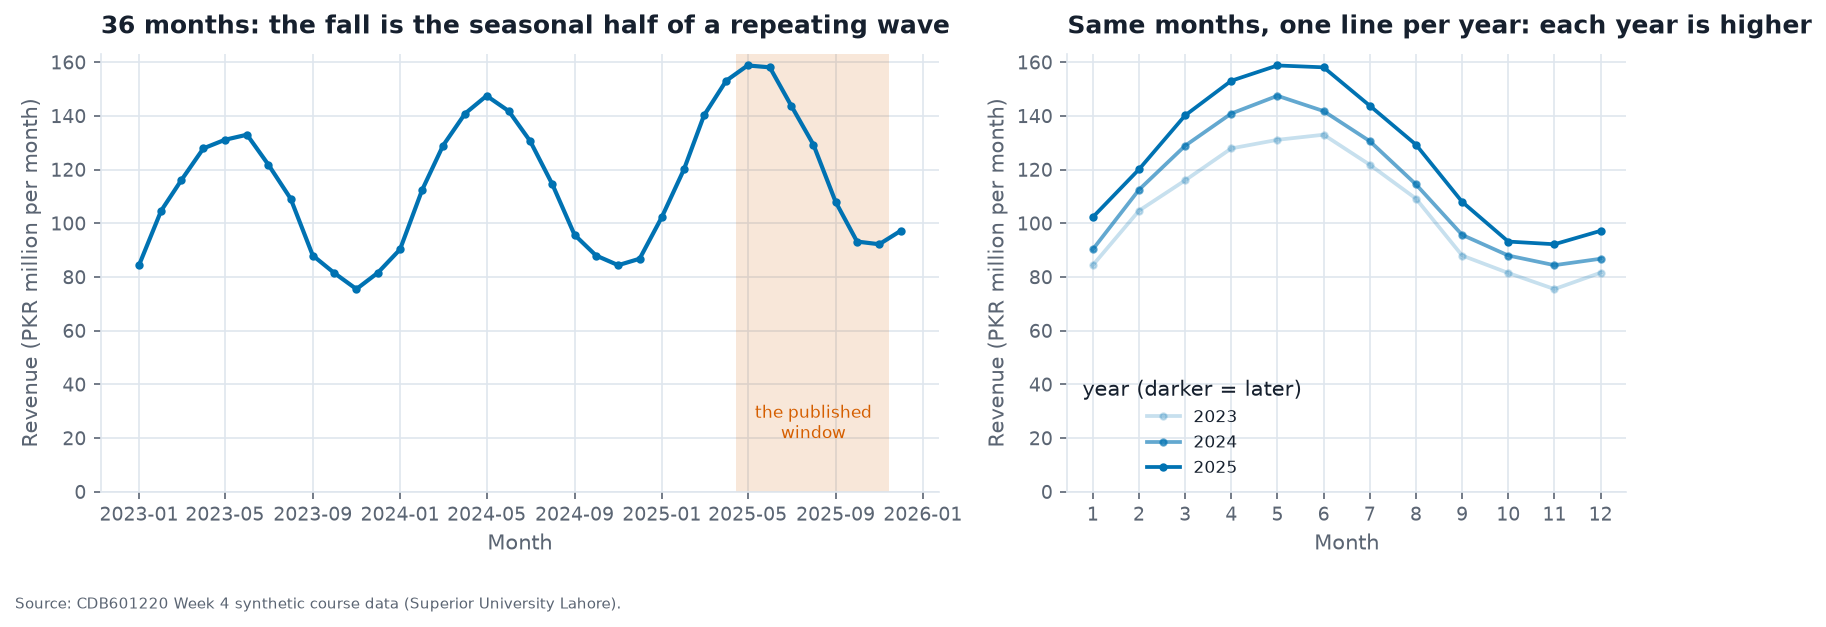

In [16]:
# ---- REDESIGN: all 36 months + a cycle plot (one line per year)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.plot(s5.index, s5, color=BLUE, marker="o", markersize=3)
ax1.axvspan(pd.Timestamp("2025-04-15"), pd.Timestamp("2025-11-15"), color=ORANGE, alpha=0.15, lw=0)
ax1.text(pd.Timestamp("2025-08-01"), 20, "the published\nwindow", ha="center", fontsize=8, color=ORANGE)
ax1.set_ylim(0, None); ax1.set_title("36 months: the fall is the seasonal half of a repeating wave")
ax1.set_xlabel("Month"); ax1.set_ylabel("Revenue (PKR million per month)")
T.cycle_plot(ax2, s5, by="month")
ax2.set_ylim(0, None); ax2.legend(title="year (darker = later)", fontsize=8)
ax2.set_title("Same months, one line per year: each year is higher")
ax2.set_ylabel("Revenue (PKR million per month)")
fig.tight_layout()
finish(fig, "case05_redesign.png")

**Conclusion the chart invites:** revenue is in a six-month collapse.

**The decoy (two of them):** "the axis is truncated" — it is not; the recipe says y from zero and the chart honours it. "Seven points is too small a sample" — the seven points are the *entire* May–November record, and `n` is not the issue: the numbers are real.

**The mechanism:** the window starts at the **seasonal peak** (May 2025, 158.8) and ends at the **seasonal trough** (November, 92.2). Any seven months from a peak to a trough fall; the same May → November fall happened in 2023 (**−42.4%**) and 2024 (**−42.8%**), almost identical to 2025's −41.9%. Against its own twin month **every one of the 12 months of 2025 is higher than 2024** (range +5.9% to +13.3%), annual revenue grows **1,254.7 → 1,361.9 → 1,496.3**, and November 2025 (92.2) is **above** November 2024 (84.4) and 2023 (75.5). The window length and start point *chose* the story.

**The redesign:** the full 36 months, with the published window shaded, plus a cycle plot that lines the months up year on year. Each year is ~9% above the last.

---
## Case 6 · "Orders collapsed in October"
`case06_monthly_partial.csv` · recipe: resample `orders` to monthly totals with `.sum()`, bars from zero. *(One of the two cases where the chart is incomplete rather than wrong.)*

bars: 10 | Sep = 10,805 | Oct = 4,041 (37% of Sep)


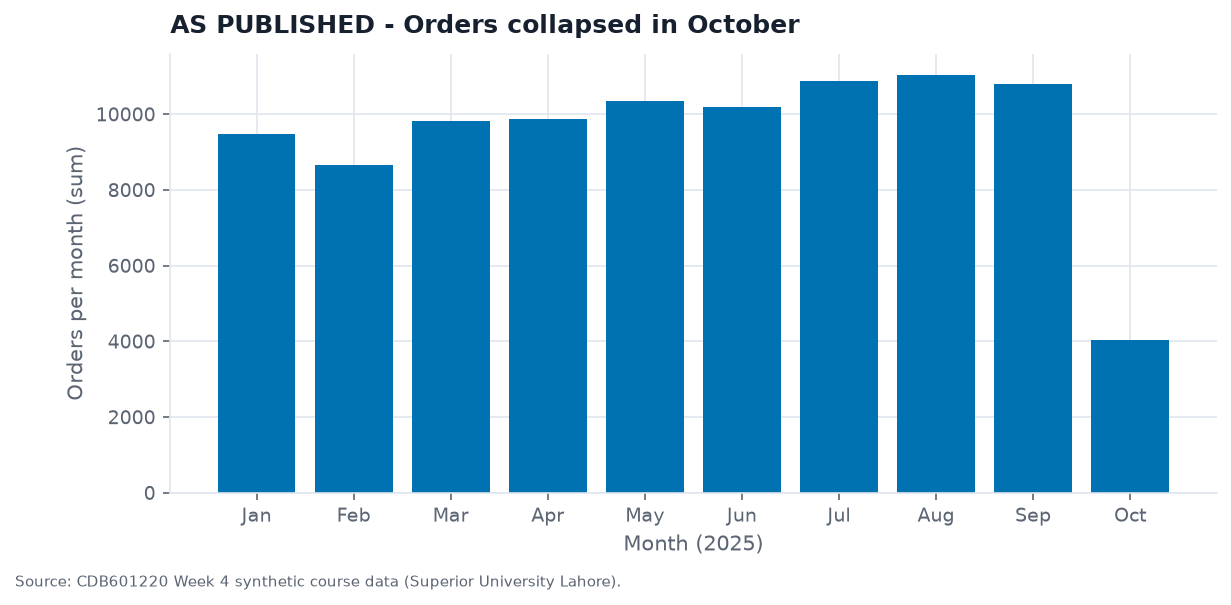

In [17]:
c6 = pd.read_csv(DATA / "case06_monthly_partial.csv", parse_dates=["date"]).set_index("date").orders
m6 = c6.resample("MS").sum()
print("bars:", len(m6), "| Sep =", f"{m6.iloc[-2]:,}", "| Oct =", f"{m6.iloc[-1]:,}", f"({m6.iloc[-1]/m6.iloc[-2]*100:.0f}% of Sep)")
assert len(m6) == 10 and m6.iloc[-2] == 10805 and m6.iloc[-1] == 4041 and round(m6.iloc[-1] / m6.iloc[-2] * 100) == 37

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(m6.index.strftime("%b"), m6, color=BLUE)
ax.set_title("AS PUBLISHED - Orders collapsed in October")
ax.set_xlabel("Month (2025)"); ax.set_ylabel("Orders per month (sum)")
finish(fig, "case06_published.png")

In [18]:
# ---- EVIDENCE
cnt6 = c6.resample("MS").count(); dim6 = c6.resample("MS").size()
print("last date in file:", c6.index.max().date(), "| days present in Oct:", int(cnt6.iloc[-1]), "of 31")
print("T.audit_index ->", {k: v for k, v in T.audit_index(c6, "D").items() if k in ("n_missing", "partial_tail", "tail_period", "tail_count")})
pd6 = c6.resample("MS").mean()
print(f"orders per DAY: Sep {pd6.iloc[-2]:.1f}  Oct {pd6.iloc[-1]:.1f}  ({(pd6.iloc[-1]/pd6.iloc[-2]-1)*100:+.1f}%)")
print(f"11/31 = {11/31*100:.1f}% of a month - the 37% bar is {m6.iloc[-1]/m6.iloc[-2]*100:.0f}% of September's total")

last date in file: 2025-10-11 | days present in Oct: 11 of 31
T.audit_index -> {'n_missing': 0, 'partial_tail': True, 'tail_period': '2025-10', 'tail_count': 11}
orders per DAY: Sep 360.2  Oct 367.4  (+2.0%)
11/31 = 35.5% of a month - the 37% bar is 37% of September's total


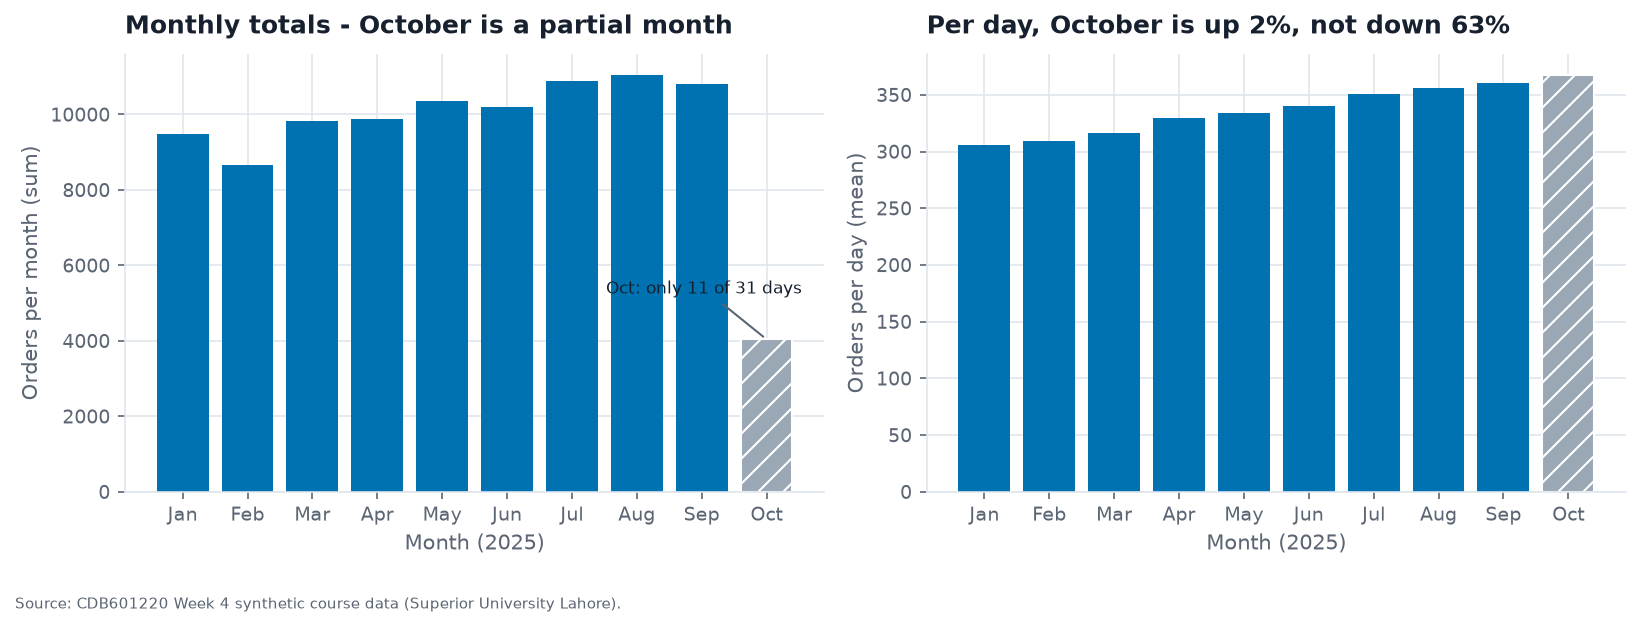

In [19]:
# ---- REDESIGN: the same bars - with October marked partial - and the per-day view beside them
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9))
lab = m6.index.strftime("%b")
cols = [BLUE] * (len(m6) - 1) + [GREY]
ax1.bar(lab, m6, color=cols); ax1.patches[-1].set_hatch("//"); ax1.patches[-1].set_edgecolor("white")
ax1.annotate("Oct: only 11 of 31 days", (len(m6) - 1, m6.iloc[-1]), textcoords="offset points",
             xytext=(-30, 22), ha="center", fontsize=8, arrowprops=dict(arrowstyle="-", color=SOFT))
ax1.set_title("Monthly totals - October is a partial month")
ax1.set_xlabel("Month (2025)"); ax1.set_ylabel("Orders per month (sum)")
ax2.bar(lab, pd6, color=cols); ax2.patches[-1].set_hatch("//"); ax2.patches[-1].set_edgecolor("white")
ax2.set_title("Per day, October is up 2%, not down 63%")
ax2.set_xlabel("Month (2025)"); ax2.set_ylabel("Orders per day (mean)")
fig.tight_layout()
finish(fig, "case06_redesign.png")

**Conclusion the chart invites:** orders fell by almost two-thirds in October.

**The decoy:** "maybe it is a real slump — check the trend before October." Nothing before October supports it: the monthly mean per day climbs steadily (334 → 367 over six months).

**The mechanism:** the file was extracted on **11 October**, so October holds **11 of 31 days**. A monthly `sum()` of an incomplete month is the sum of a fraction of a month: 11/31 = 35%, and the bar is 37% of September. Per day, October is **367.4 vs September 360.2 (+2.0%)**.

**The redesign (same chart, plus something beside it):** keep the monthly bars but draw October hatched and labelled "11 of 31 days", and put the per-day view next to it. The chart was not a wrong *type* — it was missing its denominator.

---
## Case 7 · "Product D has been erratic since mid-2024"
`case07_stacked_products.csv` · recipe: stacked area of the four products in column order, `product_a` at the bottom, `product_d` on top.

total envelope: 548 to 709


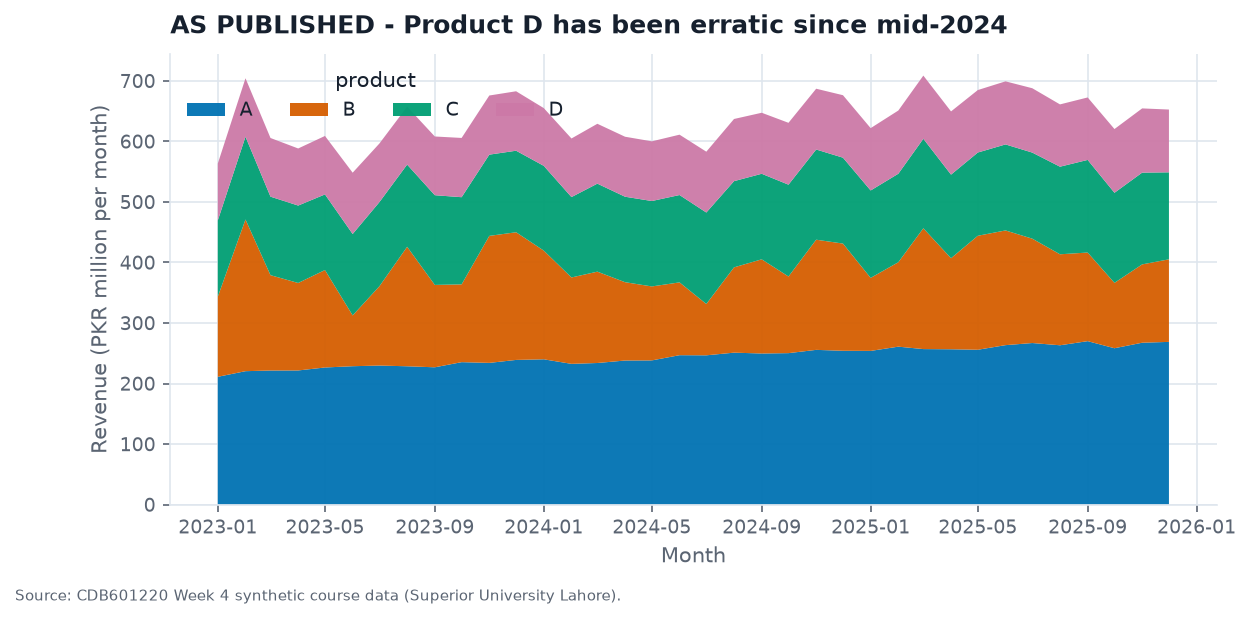

In [20]:
c7 = pd.read_csv(DATA / "case07_stacked_products.csv")
c7["when"] = pd.to_datetime(c7.month, format="%Y-%m"); p7 = c7.set_index("when").drop(columns="month")
prods = ["product_a", "product_b", "product_c", "product_d"]
tot7 = p7[prods].sum(axis=1)
print(f"total envelope: {tot7.min():.0f} to {tot7.max():.0f}")
assert round(tot7.min()) == 548 and round(tot7.max()) == 709

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.stackplot(p7.index, [p7[c] for c in prods], labels=[c[-1].upper() for c in prods],
             colors=[BLUE, ORANGE, GREEN, PINK], alpha=0.95)
ax.legend(loc="upper left", ncol=4, title="product"); ax.set_ylim(0, None)
ax.set_title("AS PUBLISHED - Product D has been erratic since mid-2024")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue (PKR million per month)")
finish(fig, "case07_published.png")

In [21]:
# ---- EVIDENCE: open the CSV - how much does each product actually move?
mv = pd.DataFrame({"mean": p7[prods].mean(), "sd": p7[prods].std(),
                   "cv_pct": p7[prods].std() / p7[prods].mean() * 100,
                   "sd_of_monthly_change": p7[prods].diff().std()}).round(2)
display(mv)
cum7 = p7[prods].cumsum(axis=1)
print(f"Product D's OWN month-to-month change:  sd = {p7.product_d.diff().std():.2f}")
print(f"Product D's LOWER EDGE on the stack (= A+B+C):  sd of change = {cum7.product_c.diff().std():.2f}  "
      f"-> {cum7.product_c.diff().std()/p7.product_d.diff().std():.0f}x more movement than D has")
print(f"if B were moved to the top, D's lower edge (= A+C) would move with sd = {(p7.product_a+p7.product_c).diff().std():.2f}")
print(f"'since mid-2024' test - D's sd before / after 2024-07: {p7.product_d[:'2024-06'].std():.2f} / {p7.product_d['2024-07':].std():.2f}")

,mean,sd,cv_pct,sd_of_monthly_change
product_a,244.49,16.01,6.55,4.68
product_b,152.41,35.61,23.36,45.81
product_c,141.05,7.28,5.16,6.43
product_d,100.34,3.55,3.54,1.97


Product D's OWN month-to-month change:  sd = 1.97
Product D's LOWER EDGE on the stack (= A+B+C):  sd of change = 47.48  -> 24x more movement than D has
if B were moved to the top, D's lower edge (= A+C) would move with sd = 8.80
'since mid-2024' test - D's sd before / after 2024-07: 1.86 / 1.71


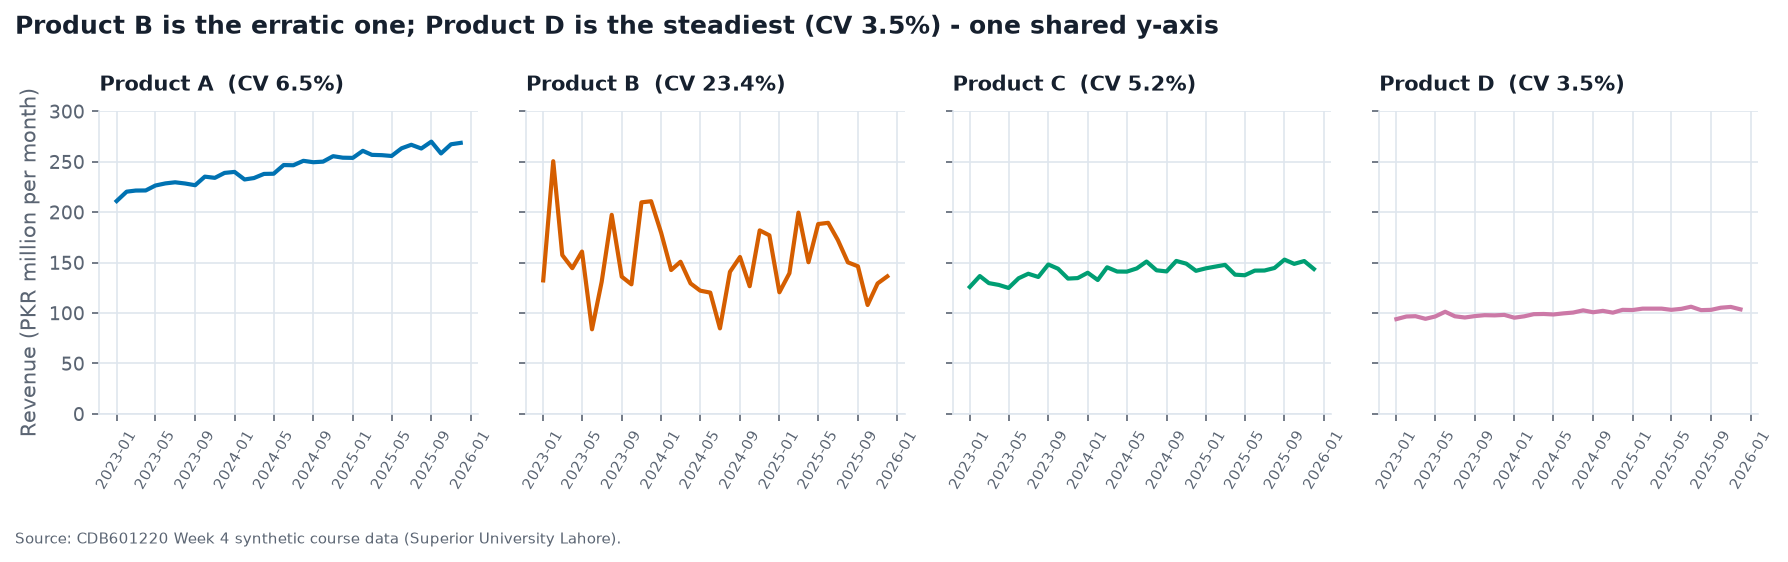

In [22]:
# ---- REDESIGN: facet - one panel per product, shared y so magnitudes stay honest
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, c, col in zip(axes, prods, [BLUE, ORANGE, GREEN, PINK]):
    ax.plot(p7.index, p7[c], color=col)
    ax.set_title(f"Product {c[-1].upper()}  (CV {p7[c].std()/p7[c].mean()*100:.1f}%)", fontsize=10)
    ax.set_ylim(0, 300); ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[0].set_ylabel("Revenue (PKR million per month)")
fig.suptitle("Product B is the erratic one; Product D is the steadiest (CV 3.5%) - one shared y-axis",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
finish(fig, "case07_redesign.png")

**Conclusion the chart invites:** Product D became unstable around mid-2024.

**The decoy:** "maybe D really did get more volatile — the wiggles are visible and they start mid-year." Test it directly: D's standard deviation is **1.86 before July 2024 and 1.71 after** — no change; its coefficient of variation is just **3.5%**, the lowest of the four.

**The mechanism:** in a stacked area the **baseline of every band is the sum of the bands beneath it**. Product B (second from the bottom) is the volatile one (CV **23%**, month-to-month sd **45.8**). It moves the baseline of C and D every month, so D's band *rides up and down* on B's noise. D's lower edge moves with sd **47.5** while D's own change has sd **1.97** — about **24×** more. The reader judges D by the wavy edge, but D's thickness barely changes. Put B on top and D's edge would move with sd 8.8; the chart type, not D, produced the story. (Product D also correlates 0.91 with A, so its visible wiggle is partly shared trend, not erratic behaviour.)

**The redesign:** **facet** — one panel per product with a *shared* y-axis (0–300) so size differences stay honest. B is the erratic line; D is nearly flat.

---
## Case 8 · "Paid search drives 43% of our customers"
`case08_channel_attrib.csv` · recipe: count `True` in each `touch_*` column ÷ number of customers, draw a four-slice pie.

{'touch_search': 42.6, 'touch_social': 32.3, 'touch_email': 27.5, 'touch_direct': 28.6}


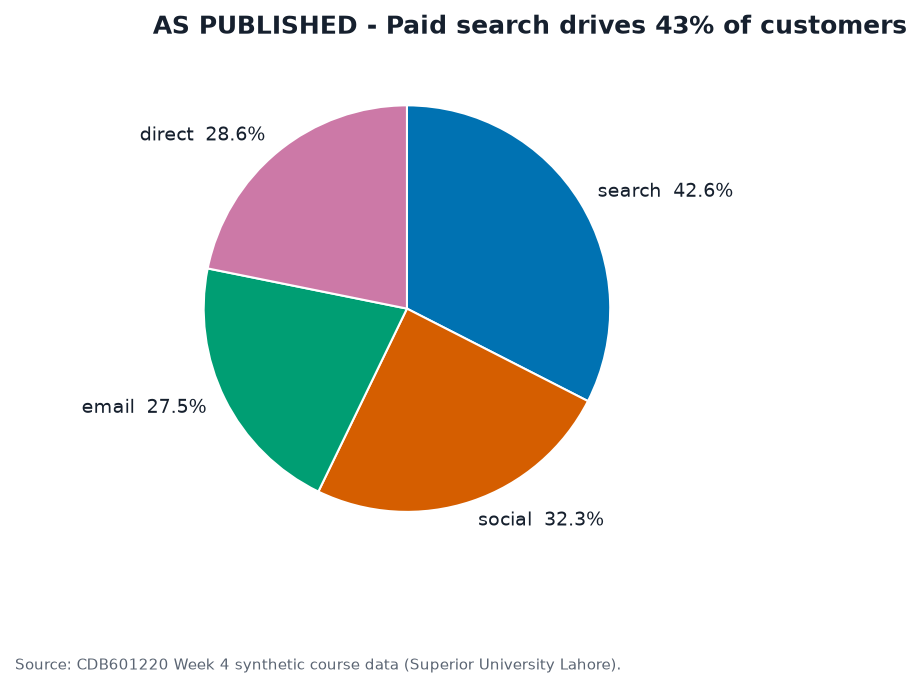

In [23]:
c8 = pd.read_csv(DATA / "case08_channel_attrib.csv")
tc = ["touch_search", "touch_social", "touch_email", "touch_direct"]
sh8 = (c8[tc].sum() / len(c8) * 100).round(1)
print(sh8.to_dict())
assert sh8.to_dict() == {"touch_search": 42.6, "touch_social": 32.3, "touch_email": 27.5, "touch_direct": 28.6}   # note 27.48 -> 27.5

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.pie(sh8, labels=[f"{n[6:]}  {v}%" for n, v in sh8.items()], startangle=90, counterclock=False,
       colors=[BLUE, ORANGE, GREEN, PINK], wedgeprops=dict(edgecolor="white"))
ax.set_title("AS PUBLISHED - Paid search drives 43% of customers")
finish(fig, "case08_published.png")

In [24]:
# ---- EVIDENCE: add up the four self-check numbers before theorising
print("sum of the four percentages:", round(float(sh8.sum()), 1), "%  (a part-to-whole must be 100)")
ex8 = T.exclusivity_check(c8, tc)
print({k: ex8[k] for k in ("n", "sum_pct", "exclusive", "n_multi", "pct_multi", "n_zero")})
k8 = c8[tc].sum(axis=1)
print("customers by number of channels that touched them:", (k8.value_counts().sort_index() / len(c8) * 100).round(1).to_dict())
print("mean channels per customer:", round(float(k8.mean()), 3), "(= the sum of the four shares / 100)")

sum of the four percentages: 131.0 %  (a part-to-whole must be 100)
{'n': 4000, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}
customers by number of channels that touched them: {1: 72.4, 2: 24.5, 3: 2.9, 4: 0.2}
mean channels per customer: 1.31 (= the sum of the four shares / 100)


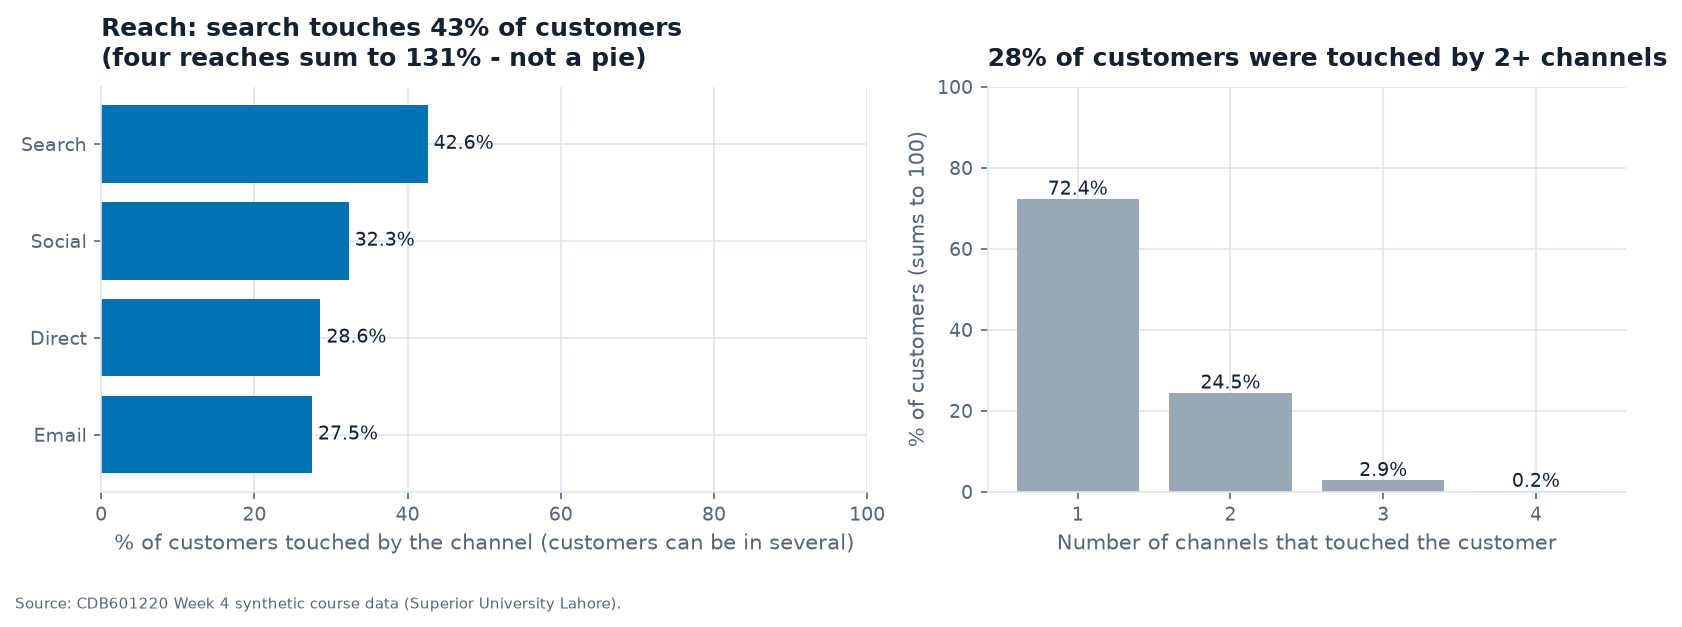

In [25]:
# ---- REDESIGN: reach per channel (not parts of a whole) + the exclusive split that DOES sum to 100%
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.2, 1]})
r8 = sh8.sort_values()
bars = ax1.barh([n[6:].title() for n in r8.index], r8, color=BLUE)
for b, v in zip(bars, r8): ax1.text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9)
ax1.set_xlim(0, 100); ax1.set_xlabel("% of customers touched by the channel (customers can be in several)")
ax1.set_title("Reach: search touches 43% of customers\n(four reaches sum to 131% - not a pie)")
t8 = (k8.value_counts().sort_index() / len(c8) * 100)
b2 = ax2.bar([str(i) for i in t8.index], t8, color=GREY)
for b, v in zip(b2, t8): ax2.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax2.set_ylim(0, 100); ax2.set_xlabel("Number of channels that touched the customer"); ax2.set_ylabel("% of customers (sums to 100)")
ax2.set_title("28% of customers were touched by 2+ channels")
fig.tight_layout()
finish(fig, "case08_redesign.png")

**Conclusion the chart invites:** four channels split the customer base, and paid search owns the biggest piece — 43% of customers.

**The decoy:** "the shares are miscomputed or customers are missing." Neither: the arithmetic is right, and **no customer has zero touches** (`n_zero = 0`). The four numbers add to **130.98%**, not 100%, which is the clue.

**The mechanism:** the parts are **not exclusive**. A customer can be touched by several channels, so each `touch_*` column is a **reach**, not a share. **1,105 of 4,000 customers (27.6%)** were touched by two or more channels (980 by two, 116 by three, 9 by four); mean channels per customer is **1.31**. A pie forces slices to sum to 100%, which these cannot. Slide-32's first test (exclusive parts) fails, so no pie, stacked bar or treemap of them is valid.

**The redesign:** sorted horizontal bars of **reach** (percent of customers touched, labelled as not summing to 100) with the exclusive split beside it — *how many channels* touched each customer — which does sum to 100%.

---
## Case 9 · "Premium is now 38% of revenue — a record"
`case09_premium_share.csv` · recipe: `premium / total` per quarter as a line, y from zero, annotate the last point. *(The second case where the chart is incomplete rather than wrong.)*

[24.0, 25.2, 26.8, 28.5, 30.5, 32.5, 35.2, 38.0]


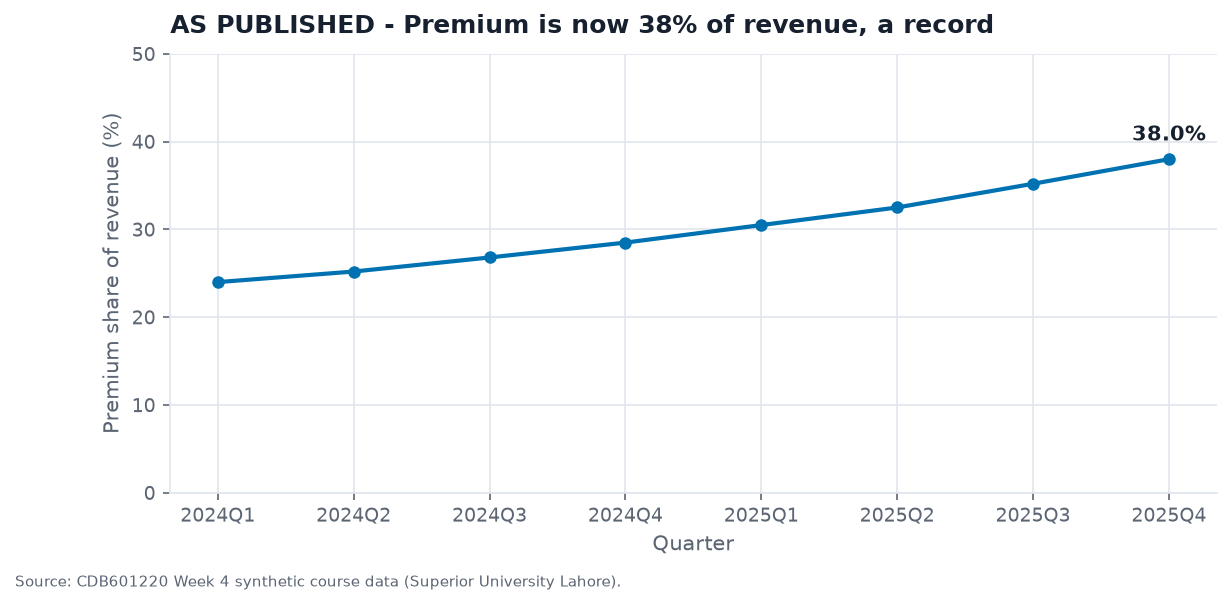

In [26]:
c9 = pd.read_csv(DATA / "case09_premium_share.csv")
c9["share"] = c9.premium_revenue_pkr_m / c9.total_revenue_pkr_m * 100
print(c9.share.round(1).tolist())
assert round(c9.share.iloc[0], 1) == 24.0 and round(c9.share.iloc[-1], 1) == 38.0

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(c9.quarter, c9.share, color=BLUE, marker="o")
ax.annotate("38.0%", (7, c9.share.iloc[-1]), textcoords="offset points", xytext=(0, 9), ha="center", fontweight="bold")
ax.set_ylim(0, 50)
ax.set_title("AS PUBLISHED - Premium is now 38% of revenue, a record")
ax.set_xlabel("Quarter"); ax.set_ylabel("Premium share of revenue (%)")
finish(fig, "case09_published.png")

In [27]:
# ---- EVIDENCE: the numerator and the denominator, separately
c9["other"] = c9.total_revenue_pkr_m - c9.premium_revenue_pkr_m
f, l = c9.iloc[0], c9.iloc[-1]
print(f"total revenue   : {f.total_revenue_pkr_m:,.0f} -> {l.total_revenue_pkr_m:,.0f}  ({(l.total_revenue_pkr_m/f.total_revenue_pkr_m-1)*100:+.0f}%)")
print(f"premium revenue : {f.premium_revenue_pkr_m:,.1f} -> {l.premium_revenue_pkr_m:,.1f}  ({(l.premium_revenue_pkr_m/f.premium_revenue_pkr_m-1)*100:+.1f}%)")
print(f"non-premium     : {f.other:,.1f} -> {l.other:,.1f}  ({(l.other/f.other-1)*100:+.0f}%)")
print("arithmetic check 228.0 / 600.0 =", round(228.0 / 600.0 * 100, 1), "%  (the share itself is computed correctly)")

total revenue   : 1,000 -> 600  (-40%)
premium revenue : 240.0 -> 228.0  (-5.0%)
non-premium     : 760.0 -> 372.0  (-51%)
arithmetic check 228.0 / 600.0 = 38.0 %  (the share itself is computed correctly)


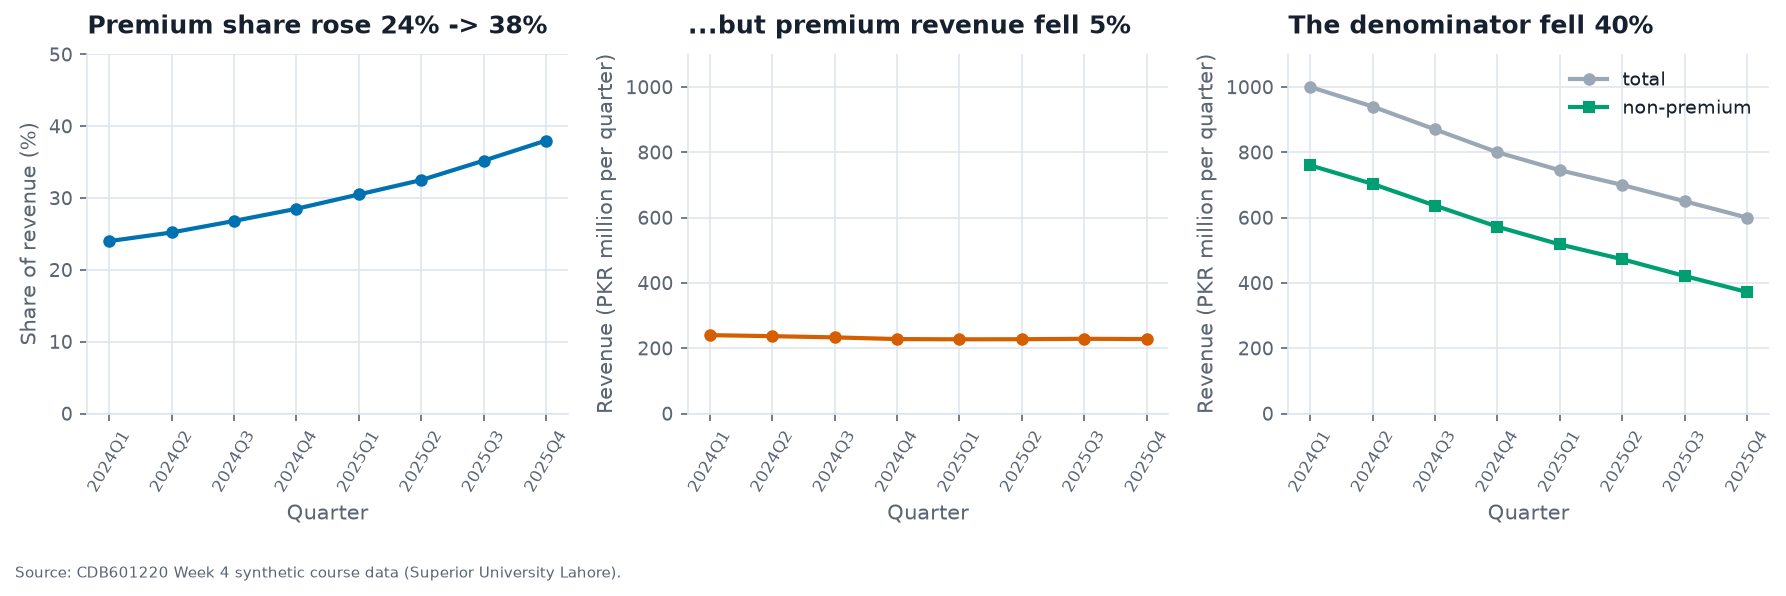

In [28]:
# ---- REDESIGN: three panels side by side (small multiples - NOT a dual y-axis)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
q = c9.quarter
axes[0].plot(q, c9.share, color=BLUE, marker="o"); axes[0].set_ylim(0, 50)
axes[0].set_title("Premium share rose 24% -> 38%"); axes[0].set_ylabel("Share of revenue (%)")
axes[1].plot(q, c9.premium_revenue_pkr_m, color=ORANGE, marker="o"); axes[1].set_ylim(0, 1100)
axes[1].set_title("...but premium revenue fell 5%"); axes[1].set_ylabel("Revenue (PKR million per quarter)")
axes[2].plot(q, c9.total_revenue_pkr_m, color=GREY, marker="o", label="total")
axes[2].plot(q, c9.other, color=GREEN, marker="s", label="non-premium"); axes[2].set_ylim(0, 1100)
axes[2].set_title("The denominator fell 40%"); axes[2].legend(); axes[2].set_ylabel("Revenue (PKR million per quarter)")
for ax in axes: ax.tick_params(axis="x", rotation=60, labelsize=8); ax.set_xlabel("Quarter")
fig.tight_layout()
finish(fig, "case09_redesign.png")

**Conclusion the chart invites:** the premium line is booming.

**The decoy:** "the share is computed wrongly." It is not — 228.0 ÷ 600.0 = 38.0% exactly, and the first quarter is 240 ÷ 1000 = 24.0%.

**The mechanism:** a share has a numerator and a denominator, and the chart shows only the ratio. **Premium revenue fell from 240.0 to 228.0 (−5.0%)**; **total revenue fell from 1,000 to 600 (−40%)**; non-premium fell **760 → 372 (−51%)**. The share rose because the *rest of the business shrank faster*, not because premium grew. "A record" is a record of the denominator collapsing.

**The redesign (same chart, plus something beside it):** the share line stays, next to the premium revenue and the total revenue it is built from — three panels, same quarters, each from zero, **no dual axis**.

---
## Summary of the nine mechanisms
| # | Claim | Mechanism | Number that proves it |
|---|---|---|---|
| 1 | Q1 peak and collapse | date column sorted as text | 0 of 23 true month-to-month falls; the two "drops" are −958, −978 |
| 2 | Steady +22% growth | row-number axis hides a 21-day recording gap | segment slopes −0.16 / +0.23 per day; step ≈ +50 |
| 3 | +43% jump on 1 July | level summed over unequal row counts | June 16.4 rows/day vs July 24; mean level −2.2% |
| 4 | Worked from 7 Sep | trailing window reports the turn ~w/2 late | lag 15 days = half of 31; raw turn ≈ 28 Aug |
| 5 | Six months of decline | window starts at seasonal peak, ends at trough | 12 of 12 months above the prior year |
| 6 | October collapse | partial final month summed | 11 of 31 days; per day +2.0% |
| 7 | D erratic | stacked baseline moves with B | D's edge sd 47.5 vs its own 1.97 |
| 8 | Search drives 43% | parts not exclusive | shares sum to 130.98%; 1,105 customers multi-touched |
| 9 | Premium a record 38% | rising share of a falling total | premium −5%, total −40% |

*All data is synthetic course data generated for CDB601220 Week 4.*